### DMW: Bogenlänge und Krümmung - Übungen

Dieses Notebook gehört zum Wahlfach **Digitale Mathematische Werkzeuge**. Es geht um zwei Größen, die man einem Graphen ansehen kann:
Wie **lang** ist ein Kurvenstück (**Bogenlänge**)? Und wie **stark gekrümmt** ist die Kurve an einer Stelle (**Krümmung**)?
Die Krümmung wird über den **Krümmungskreis** anschaulich: Er schmiegt sich an die Kurve an und hat an der Stelle dieselbe Krümmung.

Vorausgesetzt werden die Notebooks *Ableitungsregeln* und *Integrale*.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Unter den meisten Aufgaben steht das **erwartete Ergebnis**.

**Brüche und Kommazahlen:** Python rechnet `1/6` oder `0.5` sofort als Kommazahl, bevor sympy die Zahl sieht.
Die erwarteten Ausgaben sind aber mit exakten Brüchen berechnet. Schreibe solche Zahlen deshalb mit `Rational`: `Rational(1, 6)` für 1/6,
`Rational('0.5')` für 0,5. Bei einer Division ganzer Zahlen genügt es, eine davon mit `Integer` zu schreiben: `Integer(1) / 6`.
Aufgaben, bei denen das nötig ist, haben einen entsprechenden Hinweis.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

#### sympy laden

**Führe diese Zelle zuerst aus** (und nach jedem Neustart des Kernels wieder). Sie lädt sympy und matplotlib, schaltet die Formel-Ausgabe ein
und legt die reellen Variablen `x`, `h`, `s` und den Parameter `t` an.

In [ ]:
from sympy import *
init_printing()
import matplotlib.pyplot as plt
x, h, s = symbols('x h s', real=True)
t = symbols('t', real=True)

## 1. Bogenlänge

#### Vom Streckenzug zum Integral

Teilt man das Kurvenstück über [a, b] in n kleine Stücke und verbindet die Kurvenpunkte geradlinig, erhält man einen **Streckenzug**.
Seine Länge nähert die Bogenlänge an; mit wachsendem n wird die Näherung besser. Eine kleine Strecke hat nach Pythagoras die Länge
√(Δx² + Δy²) = √(1 + (Δy/Δx)²) · Δx. Im Grenzfall wird daraus das Integral für die **Bogenlänge**:

L = ∫ₐᵇ √(1 + f'(x)²) dx

Viele dieser Integrale kann man nicht genau ausrechnen. Dann schreibt man `Integral(...)` und berechnet mit `N()` einen Näherungswert.

In [ ]:
f = x**2
n = 10
punkte = [Point(Rational(i, n), f.subs(x, Rational(i, n))) for i in range(n + 1)]
streckenzug = sum([punkte[i].distance(punkte[i + 1]) for i in range(n)])
display(N(streckenzug, 6))
L = integrate(sqrt(1 + diff(f, x)**2), (x, 0, 1))
display(L, N(L, 6))
N(Integral(sqrt(1 + diff(sin(x), x)**2), (x, 0, pi)), 6)

#### Aufgabe 1.1

Berechne die Länge des Streckenzugs für f(x) = x² über [0, 1] mit n = 100 Teilstücken (6 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle 1.47894$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**2
n = 100
punkte = [Point(Rational(i, n), f.subs(x, Rational(i, n))) for i in range(n + 1)]
N(sum([punkte[i].distance(punkte[i + 1]) for i in range(n)]), 6)
```

</details>

#### Aufgabe 1.2

Schreibe eine Funktion `streckenzug(f, a, b, n)` für die Länge des Streckenzugs mit n gleich langen Teilstücken. Gib für f(x) = sin(x) über [0, π]
die Werte für n = 2, 4, 8, 16 mit 6 Ziffern als Liste aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ 3.72419, \  3.79009, \  3.81253, \  3.81827\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def streckenzug(f, a, b, n):
    xs = [a + (b - a) * Rational(i, n) for i in range(n + 1)]
    punkte = [Point(w, f.subs(x, w)) for w in xs]
    return sum([punkte[i].distance(punkte[i + 1]) for i in range(n)])

[N(streckenzug(sin(x), 0, pi, m), 6) for m in [2, 4, 8, 16]]
```

</details>

#### Aufgabe 1.3

Berechne die Bogenlänge von f(x) = x^(3/2) über [0, 4] genau und mit 5 Ziffern.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle - \frac{8}{27} + \frac{80 \sqrt{10}}{27}$

$\displaystyle 9.0734$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**Rational(3, 2)
L = integrate(sqrt(1 + diff(f, x)**2), (x, 0, 4))
display(L)
N(L, 5)
```

</details>

#### Aufgabe 1.4

Berechne die Bogenlänge der **Kettenlinie** f(x) = cosh(x) über [0, 1]. Vereinfache dazu zuerst √(1 + f'²) mit `simplify` und integriere dann.

**Erwartete Ausgabe:**

$\displaystyle \cosh{\left(x \right)}$

$\displaystyle \sinh{\left(1 \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
w = simplify(sqrt(1 + diff(cosh(x), x)**2))
display(w)
integrate(w, (x, 0, 1))
```

</details>

#### Aufgabe 1.5

Berechne die Bogenlänge der Normalparabel f(x) = x² über [−2, 2] mit 5 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle 9.2936$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
N(Integral(sqrt(1 + diff(x**2, x)**2), (x, -2, 2)), 5)
```

</details>

#### Aufgabe 1.6

Prüfe die Formel am Halbkreis f(x) = √(1 − x²) über [−1, 1], die Bogenlänge muss π sein. Von Hand vereinfacht ist √(1 + f'²) = 1/√(1 − x²).
Prüfe diese Vereinfachung an der Stelle x = 1/2 und integriere dann 1/√(1 − x²) über [−1, 1].

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle 0$

$\displaystyle \pi$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
w = sqrt(1 + diff(sqrt(1 - x**2), x)**2)
display(simplify(w.subs(x, Rational(1, 2)) - 1 / sqrt(1 - Rational(1, 4))))
integrate(1 / sqrt(1 - x**2), (x, -1, 1))
```

</details>

#### Aufgabe 1.7

Ein Seil hängt in Form von f(x) = 2 · cosh(x/2) (in m) zwischen x = −3 und x = 3. Wie lang ist es (4 Ziffern)?

**Erwartete Ausgabe:**

$\displaystyle 8.517$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
N(Integral(sqrt(1 + diff(2 * cosh(x / 2), x)**2), (x, -3, 3)), 4)
```

</details>

#### Aufgabe 1.8

**(Zusatz) Parameterkurven:** Für eine Kurve (x(t) | y(t)) ist L = ∫ √(x'(t)² + y'(t)²) dt. Berechne den Umfang des Kreises (3 cos t | 3 sin t), 0 ≤ t ≤ 2π,
und die Länge eines Bogens der **Zykloide** (t − sin t | 1 − cos t), 0 ≤ t ≤ 2π (mit `simplify` vor dem Integrieren, dann `N` mit 5 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle 6 \pi$

$\displaystyle 8.0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(integrate(simplify(sqrt(diff(3*cos(t), t)**2 + diff(3*sin(t), t)**2)), (t, 0, 2*pi)))
N(Integral(sqrt(diff(t - sin(t), t)**2 + diff(1 - cos(t), t)**2), (t, 0, 2*pi)), 5)
```

</details>

## 2. Krümmung

#### κ = f''/(1 + f'²)^(3/2)

Die **Krümmung** κ gibt an, wie schnell sich die Richtung der Kurve ändert, gemessen pro Längeneinheit des Bogens.
Für den Graphen einer Funktion gilt

κ(x) = f''(x) / (1 + f'(x)²)^(3/2)

- κ > 0: Linkskurve, κ < 0: Rechtskurve, κ = 0: gerade (z. B. im Wendepunkt)
- Eine Gerade hat überall die Krümmung 0, ein Kreis mit Radius r überall den Betrag 1/r.

Die zweite Ableitung allein reicht nicht: Bei steilen Stellen wird sie durch den Nenner „gedämpft“.

In [ ]:
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)

k = kruemmung(x**2)
display(k)
display(k.subs(x, 0), k.subs(x, 1))
display(kruemmung(sqrt(4 - x**2)).subs(x, 1))
plot(x**2, k, (x, -2, 2), legend=True);

#### Aufgabe 2.1

Berechne die Krümmung von f(x) = x³ allgemein und an den Stellen −1, 0 und 1.

**Erwartete Ausgabe:**

$\displaystyle \frac{6 x}{\left(9 x^{4} + 1\right)^{\frac{3}{2}}}$

$\displaystyle \left[ - \frac{3 \sqrt{10}}{50}, \  0, \  \frac{3 \sqrt{10}}{50}\right]$

In [ ]:
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)

k = kruemmung(x**3)
display(k)
[k.subs(x, w) for w in [-1, 0, 1]]
```

</details>

#### Aufgabe 2.2

Zeige, dass der Kreis f(x) = √(9 − x²) überall die Krümmung −1/3 hat: Werte die Krümmung an den Stellen 0, 1, 2 aus (mit `simplify`).

**Erwartete Ausgabe:**

$\displaystyle \left[ - \frac{1}{3}, \  - \frac{1}{3}, \  - \frac{1}{3}\right]$

In [ ]:
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)

[simplify(kruemmung(sqrt(9 - x**2)).subs(x, w)) for w in [0, 1, 2]]
```

</details>

#### Aufgabe 2.3

Berechne die Krümmung von f(x) = eˣ an der Stelle 0 genau und mit 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle \frac{\sqrt{2}}{4}$

$\displaystyle 0.3536$

In [ ]:
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)

k0 = kruemmung(exp(x)).subs(x, 0)
display(k0)
N(k0, 4)
```

</details>

#### Aufgabe 2.4

Wo ist die Krümmung von f(x) = eˣ am größten? Löse κ'(x) = 0 und gib die Stelle genau und mit 4 Ziffern aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ - \frac{\log{\left(2 \right)}}{2}\right]$

$\displaystyle -0.3466$

In [ ]:
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)

l = solve(diff(kruemmung(exp(x)), x), x)
display(l)
N(l[0], 4)
```

</details>

#### Aufgabe 2.5

Berechne die Krümmung der Parabel f(x) = a·x² im Scheitel in Abhängigkeit von a (a > 0).

**Erwartete Ausgabe:**

$\displaystyle 2 a$

In [ ]:
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)
a = symbols('a', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)
a = symbols('a', positive=True)
kruemmung(a * x**2).subs(x, 0)
```

</details>

#### Aufgabe 2.6

Vergleiche f''(x) und κ(x) für f(x) = x² an den Stellen 0, 1, 2, 3 (Liste von Paaren mit 4 Ziffern). Die zweite Ableitung ist konstant, die Krümmung nicht.

**Erwartete Ausgabe:**

$\displaystyle \left[ \left( 2, \  2.0\right), \  \left( 2, \  0.1789\right), \  \left( 2, \  0.02853\right), \  \left( 2, \  0.008886\right)\right]$

In [ ]:
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)

f = x**2
[(diff(f, x, 2).subs(x, w), N(kruemmung(f).subs(x, w), 4)) for w in [0, 1, 2, 3]]
```

</details>

#### Aufgabe 2.7

Zeichne f(x) = sin(x) und seine Krümmung für 0 ≤ x ≤ 2π in ein Diagramm (mit Legende).

**Erwartete Ausgabe:**



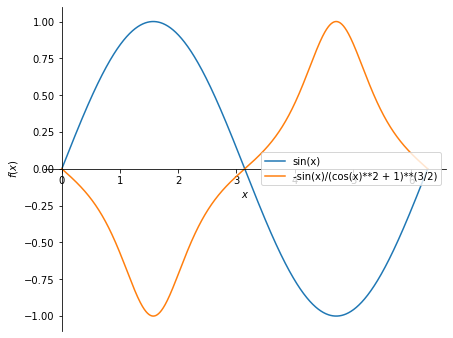

In [ ]:
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)

plot(sin(x), kruemmung(sin(x)), (x, 0, 2*pi), legend=True);
```

</details>

#### Aufgabe 2.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)

display(kruemmung(3*x + 1))
display(kruemmung(x**2 / 2).subs(x, 0))
kruemmung(-x**2 / 2).subs(x, 0)
```

In [ ]:
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)

display(kruemmung(3*x + 1))
display(kruemmung(x**2 / 2).subs(x, 0))
kruemmung(-x**2 / 2).subs(x, 0)

## 3. Der Krümmungskreis

#### Kreis durch drei benachbarte Punkte

Durch drei Punkte, die nicht auf einer Geraden liegen, geht genau ein Kreis (`Circle(P1, P2, P3)` aus `sympy.geometry`).
Nimmt man die Kurvenpunkte an den Stellen x₀ − h, x₀ und x₀ + h und lässt h kleiner werden, nähern sich diese Kreise dem **Krümmungskreis**.
Sein Radius ist r = 1/|κ(x₀)|, sein Mittelpunkt M liegt auf der Normalen auf der Seite, zu der die Kurve gekrümmt ist:

M = (x₀ − f'·(1 + f'²)/f'' | f(x₀) + (1 + f'²)/f'')  (Ableitungen an der Stelle x₀)

In [ ]:
f = x**3
x0 = 1
def P(a):
    return Point(a, f.subs(x, a))
for hh in [Rational(1, 2), Rational(1, 10), Rational(1, 100)]:
    C = Circle(P(x0 - hh), P(x0), P(x0 + hh))
    print(hh, N(C.center, 5), N(C.radius, 5))
f1, f2 = diff(f, x).subs(x, x0), diff(f, x, 2).subs(x, x0)
display((x0 - f1 * (1 + f1**2) / f2, f.subs(x, x0) + (1 + f1**2) / f2))
(1 + f1**2)**Rational(3, 2) / Abs(f2)

#### Zeichnen

Den Kreis zeichnet man als Parameterkurve (xₘ + r·cos t | yₘ + r·sin t) mit `plot_parametric`; zusammen mit dem Graphen
und gleich langen Achsen (`aspect_ratio=(1, 1)`) sieht man, wie er sich anschmiegt. Mit `p.extend(...)` fügt man einem sympy-Diagramm
weitere Kurven hinzu, `p.show()` zeigt es.

In [ ]:
f = x**2
xm, ym, r = 0, Rational(1, 2), Rational(1, 2)
p = plot(f, (x, -1.5, 1.5), show=False, aspect_ratio=(1, 1), ylim=(-0.5, 2))
p.extend(plot_parametric(xm + r * cos(t), ym + r * sin(t), (t, 0, 2*pi), show=False))
p.show()

#### Aufgabe 3.1

Schreibe eine Funktion `kreis(f, x0)`, die Mittelpunkt (als Tupel) und Radius des Krümmungskreises zurückgibt. Teste mit f(x) = x² an der Stelle 0
und an der Stelle 1.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle \left( \left( 0, \  \frac{1}{2}\right), \  \frac{1}{2}\right)$

$\displaystyle \left( \left( -4, \  \frac{7}{2}\right), \  \frac{5 \sqrt{5}}{2}\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def kreis(f, x0):
    f1, f2 = diff(f, x).subs(x, x0), diff(f, x, 2).subs(x, x0)
    M = (x0 - f1 * (1 + f1**2) / f2, f.subs(x, x0) + (1 + f1**2) / f2)
    return M, (1 + f1**2)**Rational(3, 2) / Abs(f2)

display(kreis(x**2, 0))
kreis(x**2, 1)
```

</details>

#### Aufgabe 3.2

Bestimme den Krümmungskreis von f(x) = eˣ an der Stelle 0 (Mittelpunkt und Radius).

**Erwartete Ausgabe:**

$\displaystyle \left( \left( -2, \  3\right), \  2 \sqrt{2}\right)$

In [ ]:
def kreis(f, x0):
    f1, f2 = diff(f, x).subs(x, x0), diff(f, x, 2).subs(x, x0)
    M = (x0 - f1 * (1 + f1**2) / f2, f.subs(x, x0) + (1 + f1**2) / f2)
    return M, (1 + f1**2)**Rational(3, 2) / Abs(f2)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def kreis(f, x0):
    f1, f2 = diff(f, x).subs(x, x0), diff(f, x, 2).subs(x, x0)
    M = (x0 - f1 * (1 + f1**2) / f2, f.subs(x, x0) + (1 + f1**2) / f2)
    return M, (1 + f1**2)**Rational(3, 2) / Abs(f2)

kreis(exp(x), 0)
```

</details>

#### Aufgabe 3.3

Bestimme den Krümmungskreis von f(x) = sin(x) an der Stelle π/2.

**Erwartete Ausgabe:**

$\displaystyle \left( \left( \frac{\pi}{2}, \  0\right), \  1\right)$

In [ ]:
def kreis(f, x0):
    f1, f2 = diff(f, x).subs(x, x0), diff(f, x, 2).subs(x, x0)
    M = (x0 - f1 * (1 + f1**2) / f2, f.subs(x, x0) + (1 + f1**2) / f2)
    return M, (1 + f1**2)**Rational(3, 2) / Abs(f2)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def kreis(f, x0):
    f1, f2 = diff(f, x).subs(x, x0), diff(f, x, 2).subs(x, x0)
    M = (x0 - f1 * (1 + f1**2) / f2, f.subs(x, x0) + (1 + f1**2) / f2)
    return M, (1 + f1**2)**Rational(3, 2) / Abs(f2)

kreis(sin(x), pi/2)
```

</details>

#### Aufgabe 3.4

Berechne die Kreise durch die Punkte von f(x) = x⁴ an den Stellen 1 − h, 1, 1 + h für h = 1/2, 1/10, 1/100 und gib jeweils den Radius mit 5 Ziffern aus.
Vergleiche mit dem Radius des Krümmungskreises an der Stelle 1 (mit `kreis` von oben, 5 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle \left[ 7.0962, \  5.8873, \  5.8415\right]$

$\displaystyle 5.8411$

In [ ]:
def kreis(f, x0):
    f1, f2 = diff(f, x).subs(x, x0), diff(f, x, 2).subs(x, x0)
    M = (x0 - f1 * (1 + f1**2) / f2, f.subs(x, x0) + (1 + f1**2) / f2)
    return M, (1 + f1**2)**Rational(3, 2) / Abs(f2)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def kreis(f, x0):
    f1, f2 = diff(f, x).subs(x, x0), diff(f, x, 2).subs(x, x0)
    M = (x0 - f1 * (1 + f1**2) / f2, f.subs(x, x0) + (1 + f1**2) / f2)
    return M, (1 + f1**2)**Rational(3, 2) / Abs(f2)

def P(a):
    return Point(a, a**4)

display([N(Circle(P(1 - hh), P(1), P(1 + hh)).radius, 5) for hh in [Rational(1, 2), Rational(1, 10), Rational(1, 100)]])
N(kreis(x**4, 1)[1], 5)
```

</details>

#### Aufgabe 3.5

Zeichne f(x) = x³ und seinen Krümmungskreis an der Stelle x₀ = 1 (Mittelpunkt (−4 | 8/3), Radius 5√10/3) wie im Beispiel (−9 ≤ x ≤ 2, y von −3 bis 9).

**Erwartete Ausgabe:**



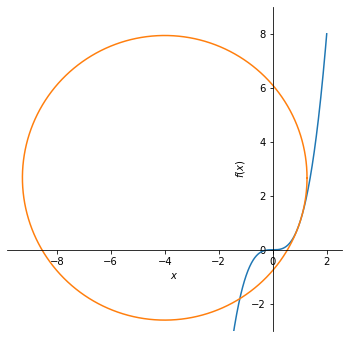

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
p = plot(x**3, (x, -9, 2), show=False, aspect_ratio=(1, 1), ylim=(-3, 9))
r = 5 * sqrt(10) / 3
p.extend(plot_parametric(-4 + r * cos(t), Rational(8, 3) + r * sin(t), (t, 0, 2*pi), show=False))
p.show()
```

</details>

#### Aufgabe 3.6

**Ellipse:** Der obere Bogen der Ellipse x²/4 + y² = 1 ist f(x) = √(1 − x²/4). Berechne die Radien der Krümmungskreise am Scheitel (0 | 1) und nahe am Ende (x = 1,9),
mit 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle \left[ 4.0, \  0.7347\right]$

In [ ]:
def kreis(f, x0):
    f1, f2 = diff(f, x).subs(x, x0), diff(f, x, 2).subs(x, x0)
    M = (x0 - f1 * (1 + f1**2) / f2, f.subs(x, x0) + (1 + f1**2) / f2)
    return M, (1 + f1**2)**Rational(3, 2) / Abs(f2)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def kreis(f, x0):
    f1, f2 = diff(f, x).subs(x, x0), diff(f, x, 2).subs(x, x0)
    M = (x0 - f1 * (1 + f1**2) / f2, f.subs(x, x0) + (1 + f1**2) / f2)
    return M, (1 + f1**2)**Rational(3, 2) / Abs(f2)

f = sqrt(1 - x**2 / 4)
[N(kreis(f, w)[1], 4) for w in [0, Rational(19, 10)]]
```

</details>

## 4. Der Krümmungskreis als beste Annäherung

#### Gleiche Werte bis zur zweiten Ableitung

Die **Tangente** stimmt an der Stelle x₀ mit f im Funktionswert und in der ersten Ableitung überein (beste Gerade).
Der **Krümmungskreis** stimmt sogar im Funktionswert, in der ersten **und** in der zweiten Ableitung überein: Er ist der Kreis, der sich am besten anschmiegt.

Prüfen: Den unteren Halbkreis um M(xₘ | yₘ) mit Radius r beschreibt g(x) = yₘ − √(r² − (x − xₘ)²) (oberer: +).
Man vergleicht g, g', g'' an der Stelle x₀ mit f, f', f''.

In [ ]:
f = x**2
xm, ym, r = 0, Rational(1, 2), Rational(1, 2)
g = ym - sqrt(r**2 - (x - xm)**2)
display([f.subs(x, 0), diff(f, x).subs(x, 0), diff(f, x, 2).subs(x, 0)])
[g.subs(x, 0), diff(g, x).subs(x, 0), diff(g, x, 2).subs(x, 0)]

#### Aufgabe 4.1

Prüfe für f(x) = eˣ an der Stelle 0: Der Krümmungskreis hat den Mittelpunkt (−2 | 3) und den Radius 2√2. Vergleiche f, f', f'' mit g, g', g'' des **unteren** Halbkreises.

**Erwartete Ausgabe:**

$\displaystyle \left[ 1, \  1, \  1\right]$

$\displaystyle \left[ 1, \  1, \  1\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = exp(x)
g = 3 - sqrt(8 - (x + 2)**2)
display([f.subs(x, 0), diff(f, x).subs(x, 0), diff(f, x, 2).subs(x, 0)])
[simplify(g.subs(x, 0)), simplify(diff(g, x).subs(x, 0)), simplify(diff(g, x, 2).subs(x, 0))]
```

</details>

#### Aufgabe 4.2

Ein anderer Kreis durch (0 | 1) mit derselben Tangente: Mittelpunkt (−1 | 2), Radius √2. Vergleiche g'' an der Stelle 0 mit f''(0) = 1. (Er stimmt nur bis zur ersten Ableitung.)

**Erwartete Ausgabe:**

$\displaystyle \left[ 1, \  1, \  2\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
g = 2 - sqrt(2 - (x + 1)**2)
[simplify(g.subs(x, 0)), simplify(diff(g, x).subs(x, 0)), simplify(diff(g, x, 2).subs(x, 0))]
```

</details>

#### Aufgabe 4.3

Zeichne f(x) = eˣ, die Tangente y = x + 1 und den unteren Bogen des Krümmungskreises g(x) = 3 − √(8 − (x + 2)²) für −2 ≤ x ≤ 1 in ein Diagramm (mit Legende).

**Erwartete Ausgabe:**



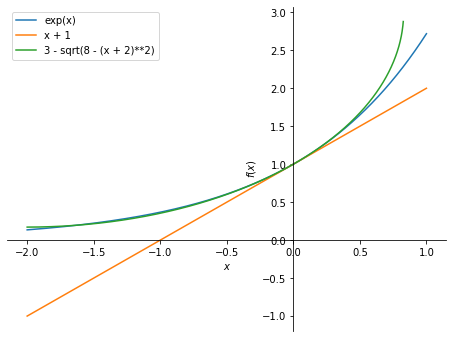

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(exp(x), x + 1, 3 - sqrt(8 - (x + 2)**2), (x, -2, 1), legend=True);
```

</details>

#### Aufgabe 4.4

Wie gut nähern Tangente und Krümmungskreis f(x) = eˣ bei x = 0,2 an? Gib die Fehler |f − Tangente| und |f − g| mit 3 Ziffern aus.

**Erwartete Ausgabe:**

$\displaystyle 0.0214$

$\displaystyle 0.000958$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
w = Rational(1, 5)
display(N(Abs(exp(w) - (w + 1)), 3))
N(Abs(exp(w) - (3 - sqrt(8 - (w + 2)**2))), 3)
```

</details>

## 5. Anwendung: Übergangsbögen

#### Kein Krümmungssprung

Fährt ein Auto oder Zug von einer Geraden (κ = 0) direkt in einen Kreisbogen (κ = 1/r), springt die Krümmung. Man müsste das Lenkrad
schlagartig drehen, im Zug spürt man einen Ruck. Deshalb baut man **Übergangsbögen**, deren Krümmung stetig von 0 auf 1/r wächst.

Beispiel: Ein Bogen f(x) = a·x³ für x ≥ 0 schließt an die x-Achse (x ≤ 0) ohne Knick **und** ohne Krümmungssprung an:
f(0) = 0, f'(0) = 0, κ(0) = 0.

In [ ]:
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)

f = x**3 / 30
display([f.subs(x, 0), diff(f, x).subs(x, 0), kruemmung(f).subs(x, 0)])
display([N(kruemmung(f).subs(x, w), 3) for w in [1, 2, 3]])
g = x**2 / 2
[g.subs(x, 0), diff(g, x).subs(x, 0), kruemmung(g).subs(x, 0)]

#### Aufgabe 5.1

Prüfe, ob der Anschluss von f(x) = x²/10 (x ≥ 0) an die x-Achse (x ≤ 0) einen Krümmungssprung hat: Gib f(0), f'(0) und κ(0) aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ 0, \  0, \  \frac{1}{5}\right]$

In [ ]:
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)

f = x**2 / 10
[f.subs(x, 0), diff(f, x).subs(x, 0), kruemmung(f).subs(x, 0)]
```

</details>

#### Aufgabe 5.2

Bestimme a so, dass der Übergangsbogen f(x) = a·x³ an der Stelle x = 2 die Krümmung 1/10 hat (4 Ziffern). Es gibt zwei Lösungen; gesucht ist die kleine
(flacher Bogen). Mit einem Startwert findet `nsolve` hier die große. Suche deshalb im Intervall [0; 0,05] mit dem **Bisektionsverfahren**:
`nsolve(term, a, (0, 0.05), solver='bisect')`.

**Erwartete Ausgabe:**

$\displaystyle 0.008463$

In [ ]:
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)
a = symbols('a', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)
a = symbols('a', positive=True)
N(nsolve(kruemmung(a * x**3).subs(x, 2) - Rational(1, 10), a, (0, 0.05), solver='bisect'), 4)
```

</details>

#### Aufgabe 5.3

Zeichne die Krümmung des Übergangsbogens f(x) = x³/30 für 0 ≤ x ≤ 6.

**Erwartete Ausgabe:**



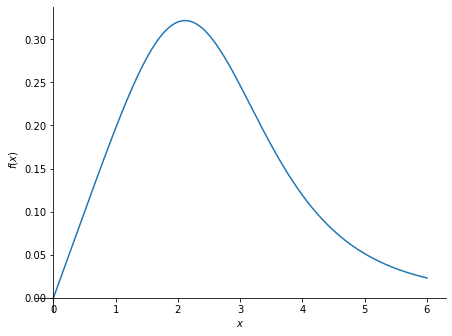

In [ ]:
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)

plot(kruemmung(x**3 / 30), (x, 0, 6));
```

</details>

#### Aufgabe 5.4

Eine Straße verläuft für x ≤ 0 auf der x-Achse. Ein Übergangsbogen f(x) = a·x³ + b·x⁴ soll an der Stelle x = 1 die Steigung 1/2 und die Krümmung 0 haben.
Bestimme a und b (zwei Gleichungen, `solve`) und gib zur Kontrolle κ(0) aus.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle \left\{ a : \frac{1}{2}, \  b : - \frac{1}{4}\right\}$

$\displaystyle 0$

In [ ]:
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def kruemmung(f):
    return diff(f, x, 2) / (1 + diff(f, x)**2)**Rational(3, 2)

a, b = symbols('a b', real=True)
f = a * x**3 + b * x**4
l = solve([Eq(diff(f, x).subs(x, 1), Rational(1, 2)), Eq(diff(f, x, 2).subs(x, 1), 0)], [a, b])
display(l)
kruemmung(f.subs(l)).subs(x, 0)
```

</details>